In [6]:
import pandas as pd
import numpy as np
import re
import os
import sys
import json

import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append("../functions/")
import networks

In [7]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [9]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"__91__e__93__" for met in compounds]

In [10]:
results_abundance = {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_abundance/"):
    if file.endswith(".tsv") and not file.endswith("_growth.tsv"):
        results_abundance[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_abundance/"+file,sep="\t")

results_abundance_df = pd.concat(results_abundance)
results_abundance_df = results_abundance_df.reset_index(drop=True)

In [12]:
results = results_abundance_df.copy()

results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results = results[~results.compound.isin(m9_compounds)]

In [13]:
abundances_exp_list = []

for file in os.listdir("../data/Venturelli2018/generated/communities_steadiercom/"):
    if file.endswith(".tsv"):
        
        abundance = pd.read_csv("../data/Venturelli2018/generated/communities_steadiercom/"+file,sep="\t",header=None)
        
        abundances_exp_list.append(abundance)
        
        
abundances_exp = pd.concat(abundances_exp_list)

In [14]:
abundances_exp.columns = ["community","member","abundance"]

abundances_exp = abundances_exp.set_index(["community","member"])["abundance"]
abundances_exp = abundances_exp.unstack().T

### Out degree (frequency)

In [15]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


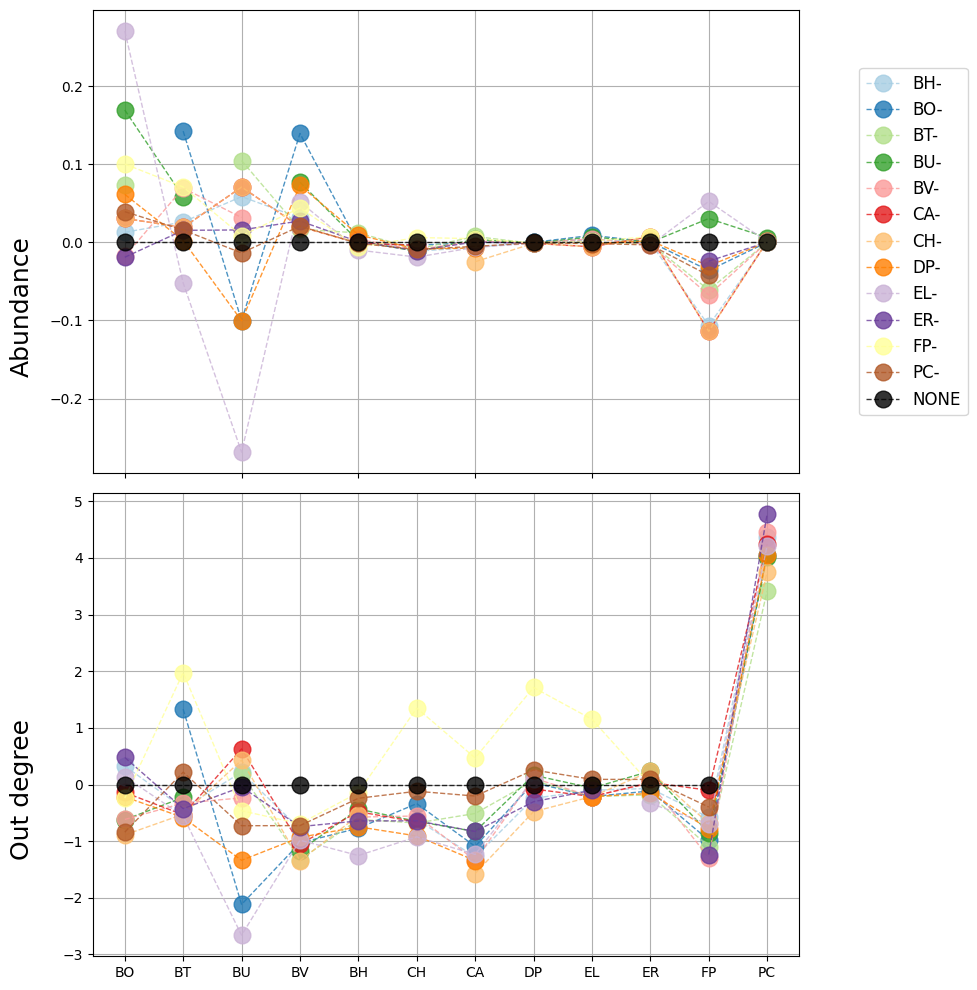

In [17]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = (abundances_exp.T-abundances_exp["NONE"]).T.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
(abundances_exp["NONE"]-abundances_exp["NONE"]).plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("Out degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()
#fig.savefig("figures/degree_comm_out.png")


### In degree (frequency)

In [18]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


In [19]:
import matplotlib.pyplot as plt

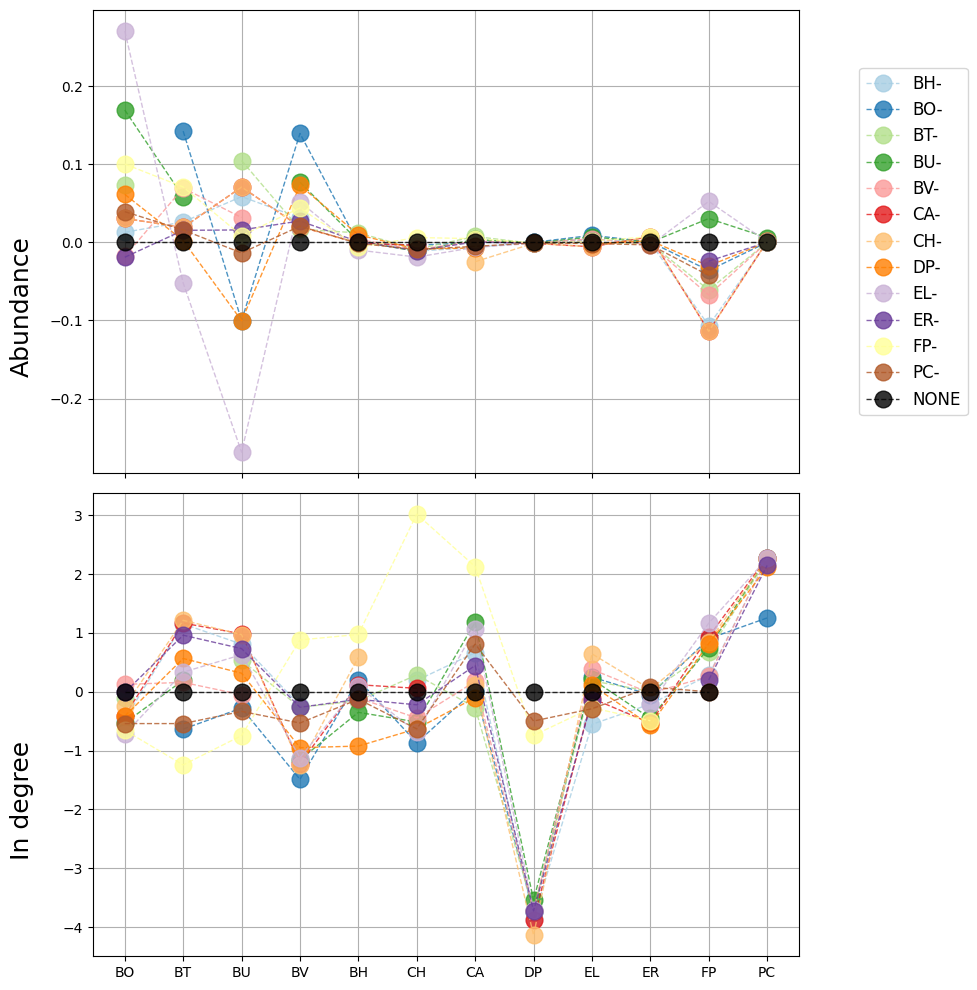

In [20]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = (abundances_exp.T-abundances_exp["NONE"]).T.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
(abundances_exp["NONE"]-abundances_exp["NONE"]).plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("In degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()


### Out degree (frequency)

In [21]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


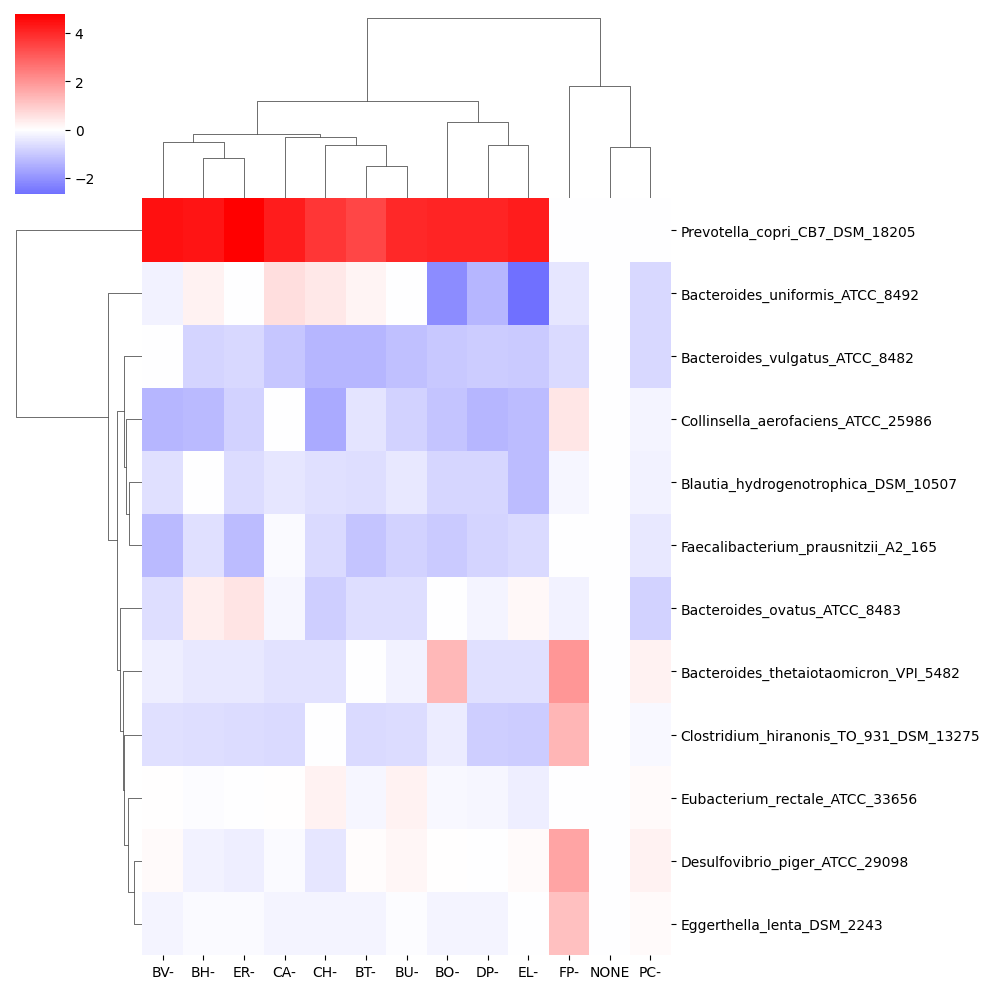

In [22]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### In degree (frequency)

In [23]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


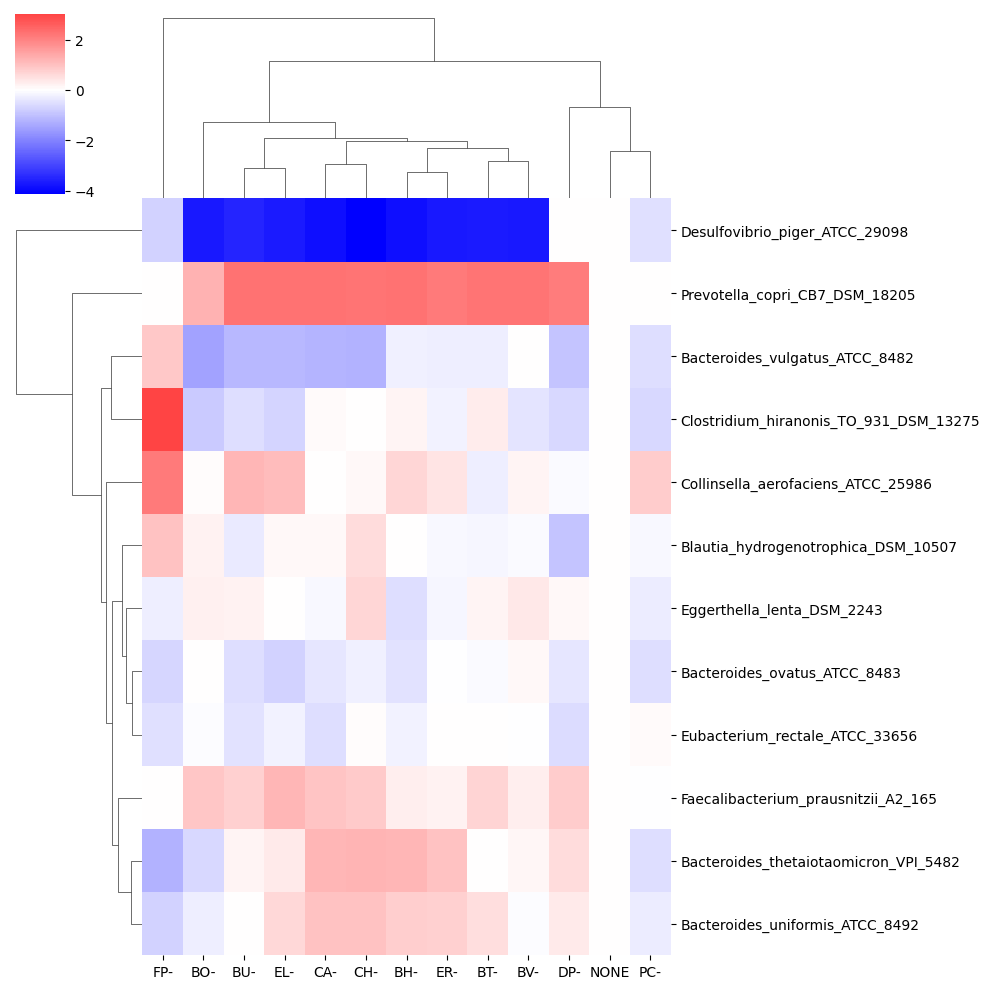

In [24]:
g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### Closeness centrality (frequency)

In [25]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["closeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


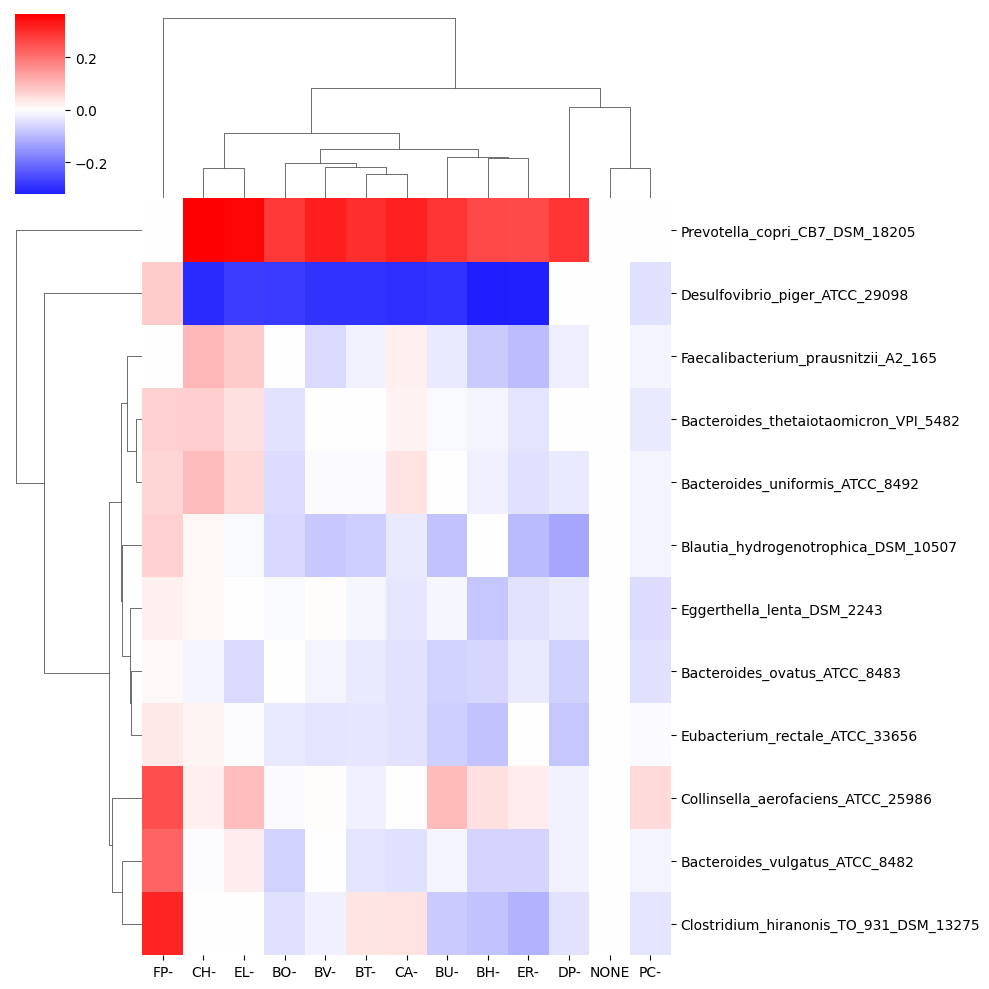

In [26]:
g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### Betweeness centrality (frequency)

In [27]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["betweeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


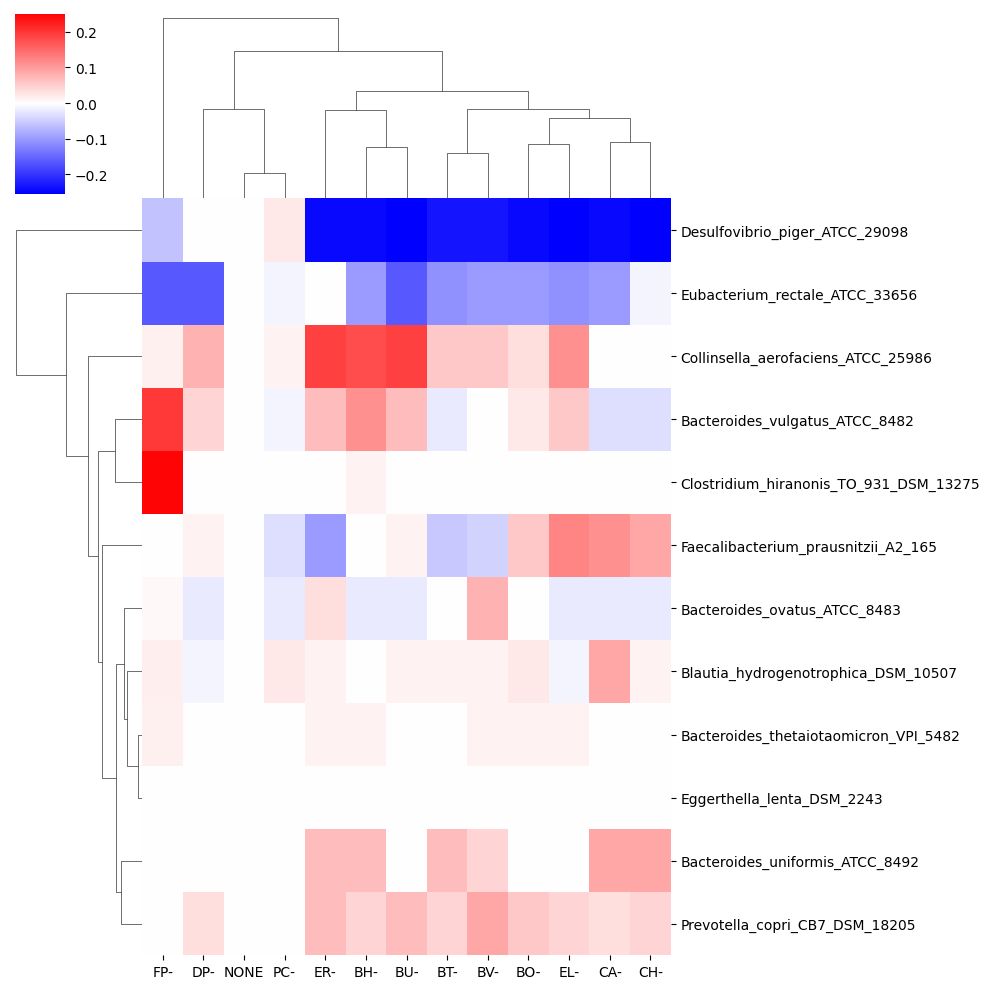

In [28]:
g = sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)